In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
img = cv2.imread("image3.jpeg")

b, g, r = cv2.split(img)

In [3]:
def my_bgr2rgb(b, g, r):
    return np.stack([r, g, b], axis=-1)


def my_bgr2gray(b, g, r):
    b = b.astype(np.int32)
    g = g.astype(np.int32)
    r = r.astype(np.int32)

    gri = (r * 9798 + g * 19235 + b * 3735 + 16384) >> 15
    return gri.astype(np.uint8)

In [4]:
rgb_opencv = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
rgb_kendi = my_bgr2rgb(b, g, r)

gri_opencv = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gri_kendi = my_bgr2gray(b, g, r)

In [5]:
hata_rgb = np.abs(rgb_opencv.astype(np.int16) - rgb_kendi.astype(np.int16)).sum()
hata_gri = np.abs(gri_opencv.astype(np.int16) - gri_kendi.astype(np.int16)).sum()

print("BGR -> RGB toplam mutlak hata:", hata_rgb)
print("BGR -> Gri toplam mutlak hata:", hata_gri)

assert hata_rgb == 0, "RGB dönüşümünde fark var."
assert hata_gri == 0, "Gri dönüşümünde fark var."

BGR -> RGB toplam mutlak hata: 0
BGR -> Gri toplam mutlak hata: 0


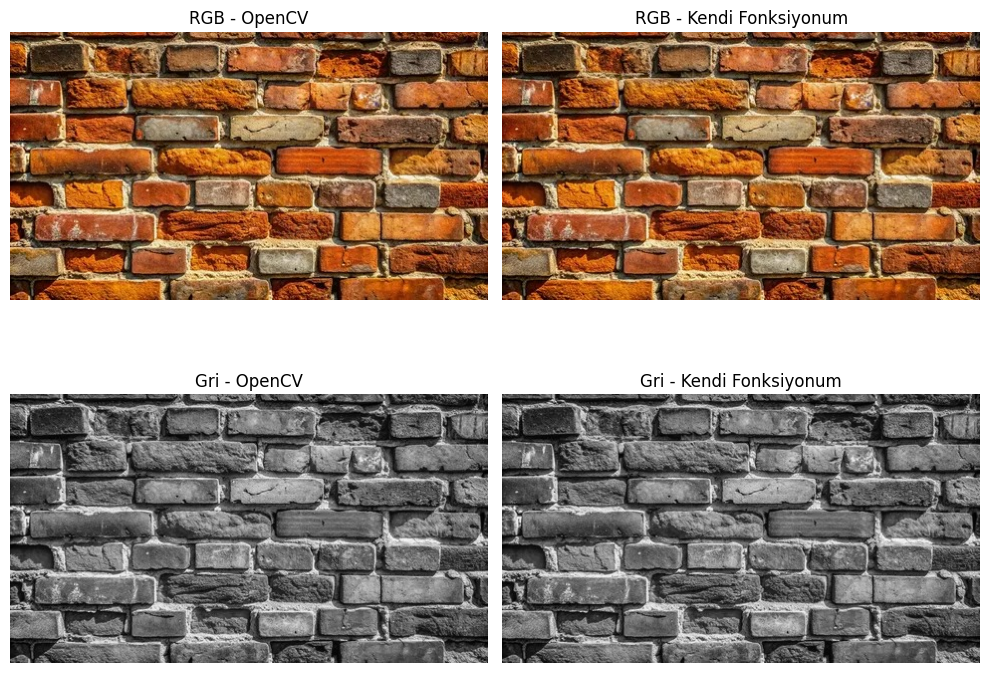

In [6]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(rgb_opencv)
plt.title("RGB - OpenCV")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(rgb_kendi)
plt.title("RGB - Kendi Fonksiyonum")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(gri_opencv, cmap="gray", vmin=0, vmax=255)
plt.title("Gri - OpenCV")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(gri_kendi, cmap="gray", vmin=0, vmax=255)
plt.title("Gri - Kendi Fonksiyonum")
plt.axis("off")

plt.tight_layout()
plt.show()